# GastroLens — Module 3: Transformer (VAE-hybrid, attention-visualized)

A generative Transformer for GI endoscopy images: patch-based self-attention encoder + probabilistic (VAE-style) latent bottleneck + attention-based decoder.

**Why VAE-style bottleneck:** a plain Transformer encoder-decoder can reconstruct but can't reliably *generate new* images from random noise (same limitation as our plain Autoencoder). Adding the mu/logvar + reparameterization step makes this genuinely generative — you can sample new z vectors and decode new images — while still using attention layers throughout, not convolutions.

**What makes this notebook different from AE/VAE:**
- Uses **perceptual loss** (VGG16 features) in addition to MSE — should produce visibly sharper output than AE/VAE, which used pixel-wise MSE only
- **Attention maps are captured and visualized** — shows exactly which patches the model focuses on, a genuinely different interpretability result
- Same NaN-safety practices learned from the VAE stage: logvar clamping, gradient clipping, mean-reduction losses, moderate learning rate

## 1. Config

In [1]:
import os

DATA_DIR = "./data_dir"
MODEL_DIR = "./models/transformer"
METRICS_DIR = "./metrics/transformer"
PLOTS_DIR = "./plots/transformer"
SYNTH_DIR = "./synthetic_data/transformer"

for d in [MODEL_DIR, METRICS_DIR, PLOTS_DIR, SYNTH_DIR]:
    os.makedirs(d, exist_ok=True)

CHECKPOINT_PATH = os.path.join(MODEL_DIR, "transformer_best.pth")
LOSS_LOG_PATH = os.path.join(METRICS_DIR, "training_loss_log.csv")
METRICS_PATH = os.path.join(METRICS_DIR, "evaluation_metrics.json")
LOSS_PLOT_PATH = os.path.join(PLOTS_DIR, "loss_curve.png")
RECON_SAMPLES_PLOT_PATH = os.path.join(PLOTS_DIR, "reconstruction_samples.png")
RANDOM_GEN_PLOT_PATH = os.path.join(PLOTS_DIR, "random_generation_samples.png")
ATTENTION_PLOT_PATH = os.path.join(PLOTS_DIR, "attention_maps.png")

# ---- Image / patch settings ----
IMG_SIZE = 128
PATCH_SIZE = 16                      # 128 / 16 = 8x8 = 64 patches
NUM_PATCHES = (IMG_SIZE // PATCH_SIZE) ** 2
EMBED_DIM = 192
NUM_HEADS = 6
NUM_ENCODER_LAYERS = 4
NUM_DECODER_LAYERS = 4
LATENT_DIM = 128                     # kept identical to AE/VAE for comparability

# ---- Training ----
BATCH_SIZE = 32                      # smaller than AE/VAE — attention is more memory-hungry
EPOCHS = 100
LEARNING_RATE = 3e-4                 # moderate, learned from the VAE NaN issue
BETA = 0.1                           # KL weight — kept lower since perceptual+MSE loss is already larger scale
PERCEPTUAL_WEIGHT = 0.1
VAL_SPLIT = 0.1
SEED = 42

FORCE_RETRAIN = False

In [2]:
import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
from torch.utils.data import DataLoader, random_split
from torchvision import datasets, transforms, models
from torchvision.utils import save_image
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import json
import time

torch.manual_seed(SEED)
np.random.seed(SEED)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Using device: {device}")

Using device: cuda


## 2. Dataset

In [3]:
transform = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.ToTensor(),
])

full_dataset = datasets.ImageFolder(root=DATA_DIR, transform=transform)
class_names = full_dataset.classes
print(f"Found {len(full_dataset)} images across {len(class_names)} classes: {class_names}")

val_size = int(len(full_dataset) * VAL_SPLIT)
train_size = len(full_dataset) - val_size
train_dataset, val_dataset = random_split(
    full_dataset, [train_size, val_size],
    generator=torch.Generator().manual_seed(SEED)
)

train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True, num_workers=2, drop_last=True)
val_loader = DataLoader(val_dataset, batch_size=BATCH_SIZE, shuffle=False, num_workers=2)

print(f"Train: {len(train_dataset)} | Val: {len(val_dataset)}")
print(f"Patches per image: {NUM_PATCHES} ({IMG_SIZE//PATCH_SIZE}x{IMG_SIZE//PATCH_SIZE} grid)")

Found 8000 images across 8 classes: ['dyed-lifted-polyps', 'dyed-resection-margins', 'esophagitis', 'normal-cecum', 'normal-pylorus', 'normal-z-line', 'polyps', 'ulcerative-colitis']
Train: 7200 | Val: 800
Patches per image: 64 (8x8 grid)


## 3. Model — patch embedding + attention-capturing Transformer blocks + VAE bottleneck
Uses `nn.MultiheadAttention` directly (rather than `nn.TransformerEncoderLayer`) specifically so we can request and keep the attention weights for visualization — the built-in layer doesn't expose them by default.

In [4]:
class AttentionBlock(nn.Module):
    """A single self-attention + feedforward block that stores its attention weights."""
    def __init__(self, embed_dim, num_heads, mlp_ratio=4):
        super().__init__()
        self.norm1 = nn.LayerNorm(embed_dim)
        self.attn = nn.MultiheadAttention(embed_dim, num_heads, batch_first=True)
        self.norm2 = nn.LayerNorm(embed_dim)
        self.mlp = nn.Sequential(
            nn.Linear(embed_dim, embed_dim * mlp_ratio),
            nn.GELU(),
            nn.Linear(embed_dim * mlp_ratio, embed_dim),
        )
        self.last_attn_weights = None  # (B, num_heads_avg, N, N) captured on each forward pass

    def forward(self, x):
        normed = self.norm1(x)
        attn_out, attn_weights = self.attn(normed, normed, normed, need_weights=True, average_attn_weights=True)
        self.last_attn_weights = attn_weights.detach()  # (B, N, N)
        x = x + attn_out
        x = x + self.mlp(self.norm2(x))
        return x


class PatchEmbed(nn.Module):
    """Splits the image into patches and linearly projects each to embed_dim, via a strided conv."""
    def __init__(self, img_size=IMG_SIZE, patch_size=PATCH_SIZE, embed_dim=EMBED_DIM):
        super().__init__()
        self.proj = nn.Conv2d(3, embed_dim, kernel_size=patch_size, stride=patch_size)
        self.grid_size = img_size // patch_size

    def forward(self, x):
        x = self.proj(x)                          # (B, embed_dim, grid, grid)
        x = x.flatten(2).transpose(1, 2)           # (B, num_patches, embed_dim)
        return x


class TransformerVAEEncoder(nn.Module):
    def __init__(self, num_patches=NUM_PATCHES, embed_dim=EMBED_DIM, num_heads=NUM_HEADS,
                 num_layers=NUM_ENCODER_LAYERS, latent_dim=LATENT_DIM):
        super().__init__()
        self.patch_embed = PatchEmbed()
        self.pos_embed = nn.Parameter(torch.randn(1, num_patches, embed_dim) * 0.02)
        self.blocks = nn.ModuleList([AttentionBlock(embed_dim, num_heads) for _ in range(num_layers)])
        self.norm = nn.LayerNorm(embed_dim)
        self.fc_mu = nn.Linear(embed_dim, latent_dim)
        self.fc_logvar = nn.Linear(embed_dim, latent_dim)

    def forward(self, x):
        x = self.patch_embed(x) + self.pos_embed
        for block in self.blocks:
            x = block(x)
        x = self.norm(x)
        pooled = x.mean(dim=1)   # mean-pool over patches -> (B, embed_dim)
        return self.fc_mu(pooled), self.fc_logvar(pooled)

    def get_attention_maps(self):
        """Returns the last forward pass's attention weights from every encoder block."""
        return [block.last_attn_weights for block in self.blocks]


class TransformerVAEDecoder(nn.Module):
    def __init__(self, num_patches=NUM_PATCHES, embed_dim=EMBED_DIM, num_heads=NUM_HEADS,
                 num_layers=NUM_DECODER_LAYERS, latent_dim=LATENT_DIM, patch_size=PATCH_SIZE):
        super().__init__()
        self.num_patches = num_patches
        self.grid_size = IMG_SIZE // patch_size
        self.patch_size = patch_size
        self.embed_dim = embed_dim

        self.fc_in = nn.Linear(latent_dim, num_patches * embed_dim)
        self.pos_embed = nn.Parameter(torch.randn(1, num_patches, embed_dim) * 0.02)
        self.blocks = nn.ModuleList([AttentionBlock(embed_dim, num_heads) for _ in range(num_layers)])
        self.norm = nn.LayerNorm(embed_dim)
        self.to_pixels = nn.Linear(embed_dim, patch_size * patch_size * 3)

    def forward(self, z):
        B = z.size(0)
        x = self.fc_in(z).view(B, self.num_patches, self.embed_dim)
        x = x + self.pos_embed
        for block in self.blocks:
            x = block(x)
        x = self.norm(x)
        patches = self.to_pixels(x)  # (B, num_patches, patch_size*patch_size*3)

        # Fold patches back into a full image
        patches = patches.view(B, self.grid_size, self.grid_size, self.patch_size, self.patch_size, 3)
        patches = patches.permute(0, 5, 1, 3, 2, 4).contiguous()  # (B, 3, gh, ph, gw, pw)
        img = patches.view(B, 3, self.grid_size * self.patch_size, self.grid_size * self.patch_size)
        return torch.sigmoid(img)

    def get_attention_maps(self):
        return [block.last_attn_weights for block in self.blocks]


class TransformerVAE(nn.Module):
    def __init__(self, latent_dim=LATENT_DIM):
        super().__init__()
        self.encoder = TransformerVAEEncoder(latent_dim=latent_dim)
        self.decoder = TransformerVAEDecoder(latent_dim=latent_dim)

    def reparameterize(self, mu, logvar):
        logvar = torch.clamp(logvar, min=-10, max=10)   # NaN-safety, learned from the VAE stage
        std = torch.exp(0.5 * logvar)
        eps = torch.randn_like(std)
        return mu + eps * std

    def forward(self, x):
        mu, logvar = self.encoder(x)
        z = self.reparameterize(mu, logvar)
        recon = self.decoder(z)
        return recon, mu, logvar


model = TransformerVAE(LATENT_DIM).to(device)
print(f"Transformer-VAE parameters: {sum(p.numel() for p in model.parameters()):,}")

Transformer-VAE parameters: 5,514,688


## 4. Loss — MSE + perceptual (VGG16 features) + KL divergence
Perceptual loss is what should push output quality visibly above AE/VAE's pixel-only MSE results.

In [5]:
class PerceptualLoss(nn.Module):
    """Compares VGG16 intermediate features of original vs. reconstruction, instead of raw pixels.
    This rewards texture/structure similarity rather than pixel-exact matching, which is what
    reduces the blur that pure MSE loss causes."""
    def __init__(self):
        super().__init__()
        vgg = models.vgg16(weights=models.VGG16_Weights.IMAGENET1K_V1).features[:16].eval()
        for p in vgg.parameters():
            p.requires_grad = False
        self.vgg = vgg
        self.register_buffer("mean", torch.tensor([0.485, 0.456, 0.406]).view(1, 3, 1, 1))
        self.register_buffer("std", torch.tensor([0.229, 0.224, 0.225]).view(1, 3, 1, 1))

    def forward(self, recon, target):
        recon_norm = (recon - self.mean) / self.std
        target_norm = (target - self.mean) / self.std
        return F.mse_loss(self.vgg(recon_norm), self.vgg(target_norm))


perceptual_loss_fn = PerceptualLoss().to(device)


def transformer_vae_loss(recon, x, mu, logvar, beta=BETA, perceptual_weight=PERCEPTUAL_WEIGHT):
    recon_loss = F.mse_loss(recon, x, reduction="mean")
    perceptual = perceptual_loss_fn(recon, x)
    kl_loss = -0.5 * torch.mean(1 + logvar - mu.pow(2) - logvar.exp())
    total = recon_loss + perceptual_weight * perceptual + beta * kl_loss
    return total, recon_loss, perceptual, kl_loss

## 5. Train (skips automatically if a checkpoint already exists)

In [6]:
def evaluate_val_loss(model, loader):
    model.eval()
    total_loss = 0.0
    with torch.no_grad():
        for imgs, _ in loader:
            imgs = imgs.to(device)
            recon, mu, logvar = model(imgs)
            loss, _, _, _ = transformer_vae_loss(recon, imgs, mu, logvar)
            total_loss += loss.item() * imgs.size(0)
    return total_loss / len(loader.dataset)


def train_transformer_vae():
    optimizer = optim.Adam(model.parameters(), lr=LEARNING_RATE)

    history = {"epoch": [], "train_loss": [], "train_recon": [], "train_perceptual": [],
               "train_kl": [], "val_loss": [], "epoch_time_sec": []}
    best_val_loss = float("inf")

    for epoch in range(1, EPOCHS + 1):
        model.train()
        start = time.time()
        running = {"loss": 0.0, "recon": 0.0, "perceptual": 0.0, "kl": 0.0}

        for imgs, _ in train_loader:
            imgs = imgs.to(device)
            optimizer.zero_grad()
            recon, mu, logvar = model(imgs)
            loss, recon_loss, perceptual, kl_loss = transformer_vae_loss(recon, imgs, mu, logvar)
            loss.backward()
            torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)  # NaN-safety
            optimizer.step()

            running["loss"] += loss.item() * imgs.size(0)
            running["recon"] += recon_loss.item() * imgs.size(0)
            running["perceptual"] += perceptual.item() * imgs.size(0)
            running["kl"] += kl_loss.item() * imgs.size(0)

        n = len(train_dataset)
        train_loss, train_recon = running["loss"] / n, running["recon"] / n
        train_perceptual, train_kl = running["perceptual"] / n, running["kl"] / n
        val_loss = evaluate_val_loss(model, val_loader)
        epoch_time = time.time() - start

        history["epoch"].append(epoch)
        history["train_loss"].append(train_loss)
        history["train_recon"].append(train_recon)
        history["train_perceptual"].append(train_perceptual)
        history["train_kl"].append(train_kl)
        history["val_loss"].append(val_loss)
        history["epoch_time_sec"].append(epoch_time)

        print(f"Epoch {epoch:3d}/{EPOCHS} | loss={train_loss:.4f} (recon={train_recon:.4f}, "
              f"perc={train_perceptual:.4f}, kl={train_kl:.4f}) | val_loss={val_loss:.4f} | {epoch_time:.1f}s")

        if val_loss < best_val_loss and not np.isnan(val_loss):
            best_val_loss = val_loss
            torch.save({
                "model_state_dict": model.state_dict(),
                "epoch": epoch,
                "val_loss": val_loss,
                "latent_dim": LATENT_DIM,
                "img_size": IMG_SIZE,
            }, CHECKPOINT_PATH)

        pd.DataFrame(history).to_csv(LOSS_LOG_PATH, index=False)

        if np.isnan(train_loss):
            print("WARNING: loss became NaN — stopping early. Consider lowering LEARNING_RATE further.")
            break

    return history


if os.path.exists(CHECKPOINT_PATH) and not FORCE_RETRAIN:
    print(f"Checkpoint found at {CHECKPOINT_PATH} — loading instead of retraining.")
    checkpoint = torch.load(CHECKPOINT_PATH, map_location=device)
    model.load_state_dict(checkpoint["model_state_dict"])
    print(f"Loaded model from epoch {checkpoint['epoch']} (val_loss={checkpoint['val_loss']:.4f})")
    history = pd.read_csv(LOSS_LOG_PATH).to_dict(orient="list") if os.path.exists(LOSS_LOG_PATH) else None
else:
    print("Training Transformer-VAE from scratch...")
    history = train_transformer_vae()
    checkpoint = torch.load(CHECKPOINT_PATH, map_location=device)
    model.load_state_dict(checkpoint["model_state_dict"])
    print(f"Loaded best checkpoint (epoch {checkpoint['epoch']}, val_loss={checkpoint['val_loss']:.4f})")

Training Transformer-VAE from scratch...
Epoch   1/100 | loss=1.3699 (recon=0.0801, perc=12.7205, kl=0.1777) | val_loss=1.1296 | 104.2s
Epoch   2/100 | loss=1.0418 (recon=0.0517, perc=9.6716, kl=0.2294) | val_loss=0.9969 | 75.5s
Epoch   3/100 | loss=0.9624 (recon=0.0420, perc=8.9871, kl=0.2168) | val_loss=0.9485 | 85.2s
Epoch   4/100 | loss=0.9237 (recon=0.0379, perc=8.6524, kl=0.2059) | val_loss=0.9145 | 60.3s
Epoch   5/100 | loss=0.8957 (recon=0.0354, perc=8.4052, kl=0.1979) | val_loss=0.8897 | 61.1s
Epoch   6/100 | loss=0.8745 (recon=0.0337, perc=8.2196, kl=0.1883) | val_loss=0.8759 | 61.4s
Epoch   7/100 | loss=0.8616 (recon=0.0326, perc=8.0990, kl=0.1911) | val_loss=0.8621 | 61.3s
Epoch   8/100 | loss=0.8497 (recon=0.0317, perc=7.9924, kl=0.1879) | val_loss=0.8516 | 61.9s
Epoch   9/100 | loss=0.8402 (recon=0.0309, perc=7.9128, kl=0.1801) | val_loss=0.8463 | 60.8s
Epoch  10/100 | loss=0.8365 (recon=0.0304, perc=7.8745, kl=0.1869) | val_loss=0.8399 | 61.0s
Epoch  11/100 | loss=0.8316

In [6]:
# ---- Load the already-trained Transformer-VAE checkpoint (no training) ----
checkpoint = torch.load(CHECKPOINT_PATH, map_location=device)
model.load_state_dict(checkpoint["model_state_dict"])
model.eval()
print(f"Loaded model from epoch {checkpoint['epoch']} (val_loss={checkpoint['val_loss']:.4f})")

# Load the loss history too, if you want the training curve without retraining
history = pd.read_csv(LOSS_LOG_PATH).to_dict(orient="list") if os.path.exists(LOSS_LOG_PATH) else None

Loaded model from epoch 99 (val_loss=0.7498)


## 6. Plot training curve

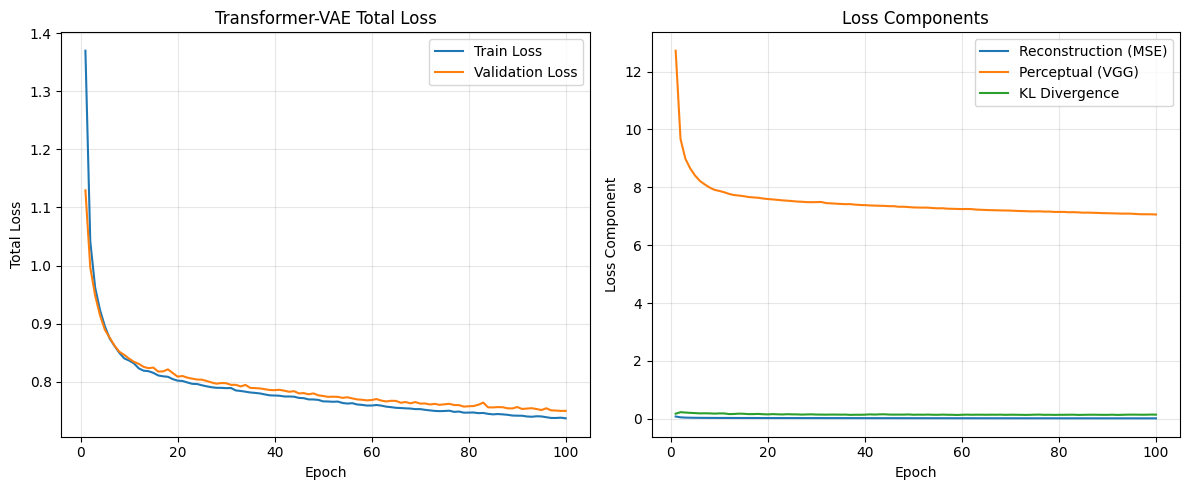

Saved loss curve to ./plots/transformer\loss_curve.png


In [7]:
if history is not None:
    fig, axes = plt.subplots(1, 2, figsize=(12, 5))
    axes[0].plot(history["epoch"], history["train_loss"], label="Train Loss")
    axes[0].plot(history["epoch"], history["val_loss"], label="Validation Loss")
    axes[0].set_xlabel("Epoch"); axes[0].set_ylabel("Total Loss")
    axes[0].set_title("Transformer-VAE Total Loss")
    axes[0].legend(); axes[0].grid(alpha=0.3)

    axes[1].plot(history["epoch"], history["train_recon"], label="Reconstruction (MSE)")
    axes[1].plot(history["epoch"], history["train_perceptual"], label="Perceptual (VGG)")
    axes[1].plot(history["epoch"], history["train_kl"], label="KL Divergence")
    axes[1].set_xlabel("Epoch"); axes[1].set_ylabel("Loss Component")
    axes[1].set_title("Loss Components")
    axes[1].legend(); axes[1].grid(alpha=0.3)

    plt.tight_layout()
    plt.savefig(LOSS_PLOT_PATH, dpi=150)
    plt.show()
    print(f"Saved loss curve to {LOSS_PLOT_PATH}")

## 7. Evaluation metrics (MSE, PSNR, SSIM)

In [8]:
from skimage.metrics import structural_similarity as ssim_fn
from skimage.metrics import peak_signal_noise_ratio as psnr_fn


def compute_reconstruction_metrics(model, loader, max_batches=None):
    model.eval()
    mse_list, psnr_list, ssim_list = [], [], []
    with torch.no_grad():
        for i, (imgs, _) in enumerate(loader):
            if max_batches is not None and i >= max_batches:
                break
            imgs = imgs.to(device)
            recon, _, _ = model(imgs)
            imgs_np, recon_np = imgs.cpu().numpy(), recon.cpu().numpy()
            for orig, rec in zip(imgs_np, recon_np):
                orig_hwc = np.transpose(orig, (1, 2, 0))
                rec_hwc = np.transpose(rec, (1, 2, 0))
                mse_list.append(np.mean((orig_hwc - rec_hwc) ** 2))
                psnr_list.append(psnr_fn(orig_hwc, rec_hwc, data_range=1.0))
                ssim_list.append(ssim_fn(orig_hwc, rec_hwc, data_range=1.0, channel_axis=2))
    return {"MSE": float(np.mean(mse_list)), "PSNR": float(np.mean(psnr_list)), "SSIM": float(np.mean(ssim_list))}


recon_metrics = compute_reconstruction_metrics(model, val_loader)
print("Reconstruction metrics (validation set):")
for k, v in recon_metrics.items():
    print(f"  {k}: {v:.4f}")

with open(METRICS_PATH, "w") as f:
    json.dump(recon_metrics, f, indent=2)
print(f"Saved metrics to {METRICS_PATH}")

Reconstruction metrics (validation set):
  MSE: 0.0165
  PSNR: 18.2841
  SSIM: 0.3662
Saved metrics to ./metrics/transformer\evaluation_metrics.json


## 8. FID setup

In [9]:
import shutil

FID_REAL_DIR = os.path.join(METRICS_DIR, "fid_real")
FID_FAKE_DIR = os.path.join(METRICS_DIR, "fid_fake")
for d in [FID_REAL_DIR, FID_FAKE_DIR]:
    if os.path.exists(d):
        shutil.rmtree(d)
    os.makedirs(d)

model.eval()
idx = 0
with torch.no_grad():
    for imgs, _ in val_loader:
        imgs = imgs.to(device)
        recon, _, _ = model(imgs)
        for orig, rec in zip(imgs, recon):
            save_image(orig, os.path.join(FID_REAL_DIR, f"{idx}.png"))
            save_image(rec, os.path.join(FID_FAKE_DIR, f"{idx}.png"))
            idx += 1

print(f"Saved {idx} real/reconstructed pairs.")
print("Run: python -m pytorch_fid", FID_REAL_DIR, FID_FAKE_DIR)

Saved 800 real/reconstructed pairs.
Run: python -m pytorch_fid ./metrics/transformer\fid_real ./metrics/transformer\fid_fake


## 9. Reconstruction samples

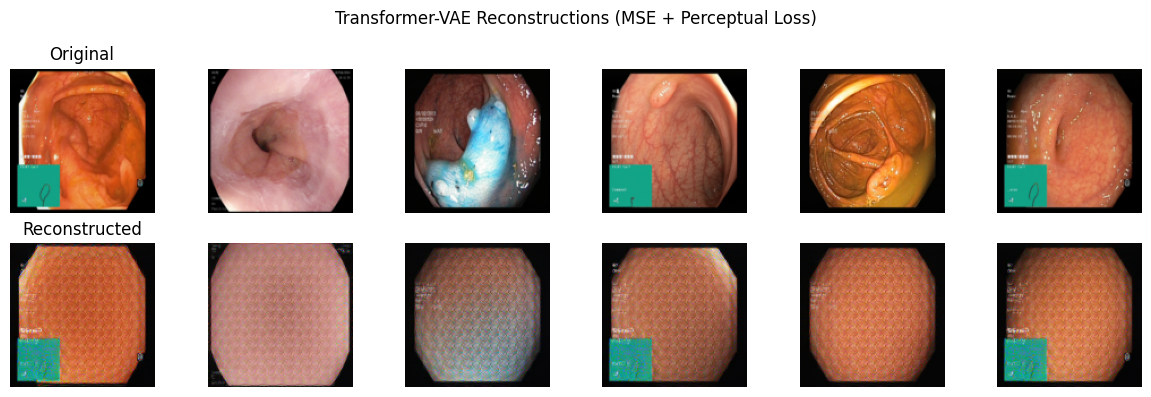

Saved reconstruction samples to ./plots/transformer\reconstruction_samples.png


In [10]:
model.eval()
imgs, labels = next(iter(val_loader))
imgs = imgs.to(device)
with torch.no_grad():
    recon, mu, logvar = model(imgs)

n_show = 6
fig, axes = plt.subplots(2, n_show, figsize=(2 * n_show, 4))
for i in range(n_show):
    axes[0, i].imshow(imgs[i].cpu().permute(1, 2, 0).numpy()); axes[0, i].axis("off")
    axes[0, i].set_title("Original" if i == 0 else "")
    axes[1, i].imshow(recon[i].cpu().permute(1, 2, 0).numpy()); axes[1, i].axis("off")
    axes[1, i].set_title("Reconstructed" if i == 0 else "")
plt.suptitle("Transformer-VAE Reconstructions (MSE + Perceptual Loss)")
plt.tight_layout()
plt.savefig(RECON_SAMPLES_PLOT_PATH, dpi=150)
plt.show()
print(f"Saved reconstruction samples to {RECON_SAMPLES_PLOT_PATH}")

## 10. Attention map visualization — this is the model's unique interpretability result
Shows, for each generated image, which patches the decoder attended to most while building the output. Overlaid directly on the reconstructed image.

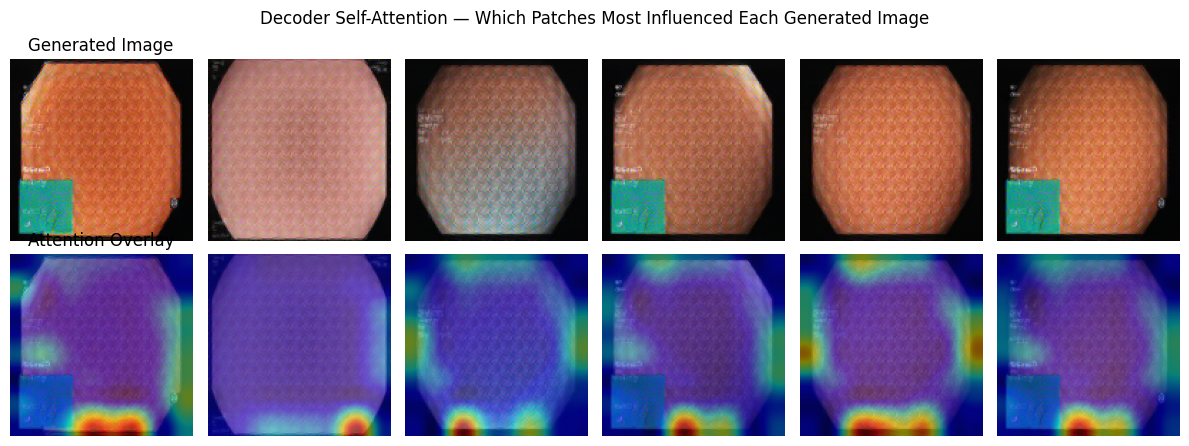

Saved attention map visualization to ./plots/transformer\attention_maps.png

Note for your report: attention weights show which regions were most predictive for reconstruction — this does not necessarily equal clinical/diagnostic importance.


In [11]:
import cv2

grid_size = IMG_SIZE // PATCH_SIZE  # 8

def attention_to_heatmap(attn_weights_single_image, grid_size=grid_size, img_size=IMG_SIZE):
    """
    attn_weights_single_image: (N, N) attention matrix for one image (already averaged over heads).
    We take the mean attention *received* by each patch (column-wise mean) as its overall importance,
    reshape to the patch grid, and upsample to full image resolution.
    """
    importance = attn_weights_single_image.mean(dim=0)          # (N,) — avg attention each patch receives
    importance = importance.reshape(grid_size, grid_size).cpu().numpy()
    heatmap = cv2.resize(importance, (img_size, img_size), interpolation=cv2.INTER_CUBIC)
    heatmap = (heatmap - heatmap.min()) / (heatmap.max() - heatmap.min() + 1e-8)
    return heatmap


# Get attention weights from the decoder's LAST block (closest to the final image — most interpretable)
decoder_attn_maps = model.decoder.get_attention_maps()
last_layer_attn = decoder_attn_maps[-1]  # (B, N, N)

n_show = 6
fig, axes = plt.subplots(2, n_show, figsize=(2 * n_show, 4.5))
for i in range(n_show):
    recon_img = recon[i].cpu().permute(1, 2, 0).numpy()
    heatmap = attention_to_heatmap(last_layer_attn[i])

    axes[0, i].imshow(recon_img); axes[0, i].axis("off")
    axes[0, i].set_title("Generated Image" if i == 0 else "")

    axes[1, i].imshow(recon_img)
    axes[1, i].imshow(heatmap, cmap="jet", alpha=0.5)
    axes[1, i].axis("off")
    axes[1, i].set_title("Attention Overlay" if i == 0 else "")

plt.suptitle("Decoder Self-Attention — Which Patches Most Influenced Each Generated Image")
plt.tight_layout()
plt.savefig(ATTENTION_PLOT_PATH, dpi=150)
plt.show()
print(f"Saved attention map visualization to {ATTENTION_PLOT_PATH}")
print("\nNote for your report: attention weights show which regions were most predictive for "
      "reconstruction — this does not necessarily equal clinical/diagnostic importance.")

## 11. Random generation — sampling from the prior (novel images)

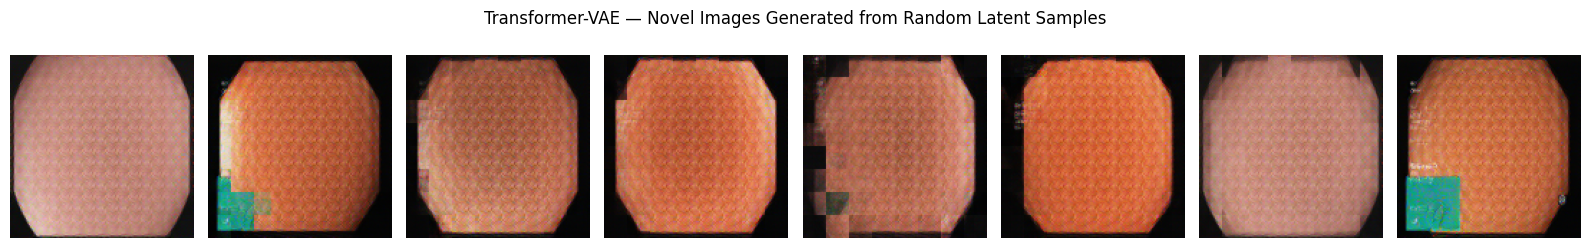

Saved random generation samples to ./plots/transformer\random_generation_samples.png
Saved 200 synthetic images to ./synthetic_data/transformer


In [12]:
model.eval()
n_gen = 8
with torch.no_grad():
    z_random = torch.randn(n_gen, LATENT_DIM).to(device)
    generated = model.decoder(z_random)

fig, axes = plt.subplots(1, n_gen, figsize=(2 * n_gen, 2.5))
for i in range(n_gen):
    axes[i].imshow(generated[i].cpu().permute(1, 2, 0).numpy())
    axes[i].axis("off")
plt.suptitle("Transformer-VAE — Novel Images Generated from Random Latent Samples")
plt.tight_layout()
plt.savefig(RANDOM_GEN_PLOT_PATH, dpi=150)
plt.show()
print(f"Saved random generation samples to {RANDOM_GEN_PLOT_PATH}")

with torch.no_grad():
    z_batch = torch.randn(200, LATENT_DIM).to(device)
    synthetic_batch = model.decoder(z_batch)
    for i, img in enumerate(synthetic_batch):
        save_image(img, os.path.join(SYNTH_DIR, f"synth_{i}.png"))
print(f"Saved 200 synthetic images to {SYNTH_DIR}")

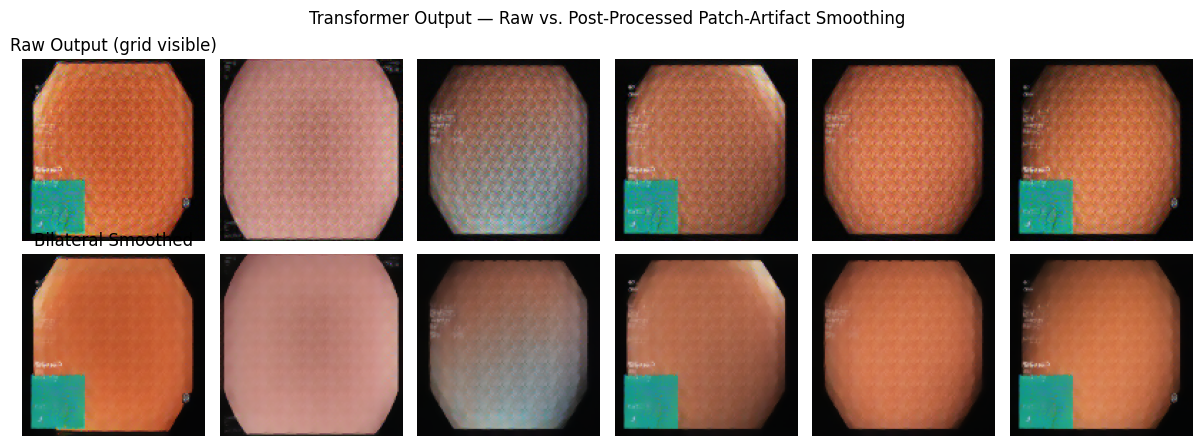

In [13]:
import cv2
import numpy as np

def smooth_patch_artifacts(img_tensor, d=9, sigma_color=50, sigma_space=50):
    """
    Reduces patch-grid artifacts using a bilateral filter — smooths flat
    noisy regions (the grid pattern) while keeping real edges intact.
    Works on the already-generated output, no retraining needed.
    """
    img_np = (img_tensor.cpu().permute(1, 2, 0).numpy() * 255).clip(0, 255).astype(np.uint8)
    smoothed = cv2.bilateralFilter(img_np, d=d, sigmaColor=sigma_color, sigmaSpace=sigma_space)
    return smoothed


# Apply to your existing generated/reconstructed samples and compare
n_show = 6
fig, axes = plt.subplots(2, n_show, figsize=(2 * n_show, 4.5))
for i in range(n_show):
    original_gen = (recon[i].cpu().permute(1, 2, 0).numpy() * 255).clip(0, 255).astype(np.uint8)
    smoothed_gen = smooth_patch_artifacts(recon[i])

    axes[0, i].imshow(original_gen); axes[0, i].axis("off")
    axes[0, i].set_title("Raw Output (grid visible)" if i == 0 else "")

    axes[1, i].imshow(smoothed_gen); axes[1, i].axis("off")
    axes[1, i].set_title("Bilateral Smoothed" if i == 0 else "")

plt.suptitle("Transformer Output — Raw vs. Post-Processed Patch-Artifact Smoothing")
plt.tight_layout()
plt.savefig(os.path.join(PLOTS_DIR, "smoothed_comparison.png"), dpi=150)
plt.show()

Loading weights: 100%|██████████| 334/334 [00:00<00:00, 2675.56it/s]


Attention shape (should NOT be empty): torch.Size([50, 50])


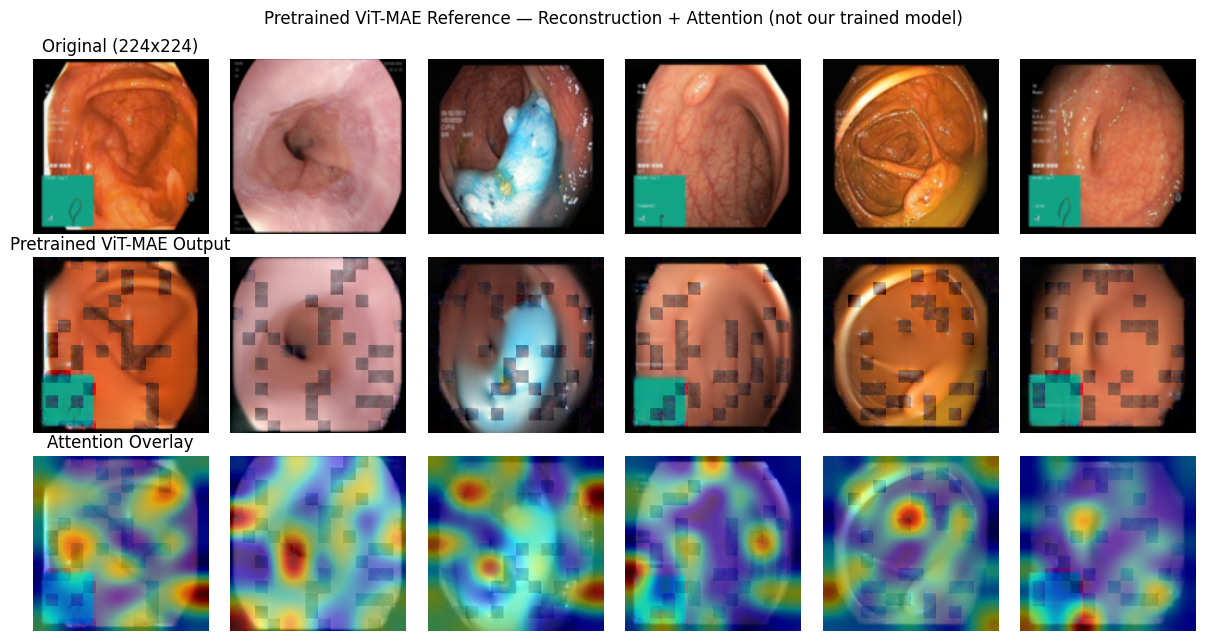

Writing model shards: 100%|██████████| 1/1 [00:01<00:00,  1.85s/it]

Saved pretrained ViT-MAE weights to ./models/transformer\pretrained_vit_mae_reference


In [16]:
# ---- Pretrained reference: ViT-MAE reconstruction + attention visualization ----
# pip install transformers
from transformers import ViTMAEForPreTraining
import torch
import torch.nn.functional as F
import numpy as np
import matplotlib.pyplot as plt
import cv2
import os

# ---- Load pretrained ViT-MAE with eager attention (needed so attention weights are actually returned) ----
try:
    pretrained_vit = ViTMAEForPreTraining.from_pretrained(
        "facebook/vit-mae-base",
        attn_implementation="eager",
    ).to(device)
except TypeError:
    # Older transformers versions don't accept attn_implementation as a kwarg — set it after loading instead
    pretrained_vit = ViTMAEForPreTraining.from_pretrained("facebook/vit-mae-base").to(device)
    pretrained_vit.config._attn_implementation = "eager"

pretrained_vit.eval()
for p in pretrained_vit.parameters():
    p.requires_grad = False

VIT_IMG_SIZE = 224
VIT_PATCH_SIZE = 16
VIT_GRID_SIZE = VIT_IMG_SIZE // VIT_PATCH_SIZE   # 14


def run_pretrained_vit_mae(img_tensor):
    """Resizes to 224x224, runs through pretrained ViT-MAE, returns the resized original,
    the reconstructed image, and the encoder's last-layer self-attention weights."""
    img_224 = F.interpolate(img_tensor.unsqueeze(0), size=(VIT_IMG_SIZE, VIT_IMG_SIZE),
                             mode="bilinear", align_corners=False).to(device)

    with torch.no_grad():
        # Reconstruction
        outputs = pretrained_vit(pixel_values=img_224, noise=None)
        recon_patches = outputs.logits
        recon_img = pretrained_vit.unpatchify(recon_patches)
        recon_img = recon_img.clamp(0, 1).squeeze(0).cpu()

        # Attention weights — pulled directly from the encoder, not the pretraining wrapper
        encoder_outputs = pretrained_vit.vit(pixel_values=img_224, output_attentions=True)

        if len(encoder_outputs.attentions) == 0:
            raise RuntimeError(
                "No attention weights returned even with eager attention. "
                "Check your transformers version with: import transformers; print(transformers.__version__)"
            )

        last_layer_attn = encoder_outputs.attentions[-1]      # (1, num_heads, seq_len, seq_len)
        avg_attn = last_layer_attn.mean(dim=1).squeeze(0)      # (seq_len, seq_len)

    return img_224.squeeze(0).cpu(), recon_img, avg_attn


def attn_to_heatmap(attn_matrix, grid_size=VIT_GRID_SIZE, img_size=VIT_IMG_SIZE):
    """Converts a (seq_len, seq_len) attention matrix into a full-image heatmap.
    Handles both the case where a CLS token is present and where it isn't, and
    falls back gracefully if the sequence length doesn't match a full grid."""
    seq_len = attn_matrix.size(0)
    expected_patches = grid_size * grid_size

    if seq_len == expected_patches + 1:
        patch_attn = attn_matrix[1:, 1:]
    elif seq_len == expected_patches:
        patch_attn = attn_matrix
    else:
        n = seq_len - 1 if seq_len > 1 else seq_len
        side = int(np.sqrt(n))
        patch_attn = attn_matrix[1:1 + side * side, 1:1 + side * side] if seq_len > side * side else attn_matrix
        grid_size = side

    importance = patch_attn.mean(dim=0)
    n_patches = grid_size * grid_size
    importance = importance[:n_patches].reshape(grid_size, grid_size).cpu().numpy()

    heatmap = cv2.resize(importance, (img_size, img_size), interpolation=cv2.INTER_CUBIC)
    heatmap = (heatmap - heatmap.min()) / (heatmap.max() - heatmap.min() + 1e-8)
    return heatmap


# ---- Sanity check before running the full batch ----
test_img_224, test_recon, test_attn = run_pretrained_vit_mae(imgs[0])
print("Attention shape (should NOT be empty):", test_attn.shape)

# ---- Run on a batch and visualize ----
n_show = 6
fig, axes = plt.subplots(3, n_show, figsize=(2 * n_show, 6.5))

for i in range(n_show):
    resized_orig, recon_224, attn = run_pretrained_vit_mae(imgs[i])
    heatmap = attn_to_heatmap(attn)

    axes[0, i].imshow(resized_orig.permute(1, 2, 0).numpy()); axes[0, i].axis("off")
    axes[0, i].set_title("Original (224x224)" if i == 0 else "")

    axes[1, i].imshow(recon_224.permute(1, 2, 0).numpy()); axes[1, i].axis("off")
    axes[1, i].set_title("Pretrained ViT-MAE Output" if i == 0 else "")

    axes[2, i].imshow(recon_224.permute(1, 2, 0).numpy())
    axes[2, i].imshow(heatmap, cmap="jet", alpha=0.5)
    axes[2, i].axis("off")
    axes[2, i].set_title("Attention Overlay" if i == 0 else "")

plt.suptitle("Pretrained ViT-MAE Reference — Reconstruction + Attention (not our trained model)")
plt.tight_layout()
plt.savefig(os.path.join(PLOTS_DIR, "pretrained_vit_mae_reference.png"), dpi=150)
plt.show()

# ---- Save the pretrained model locally so future runs don't need internet ----
PRETRAINED_VIT_SAVE_DIR = os.path.join(MODEL_DIR, "pretrained_vit_mae_reference")
os.makedirs(PRETRAINED_VIT_SAVE_DIR, exist_ok=True)
pretrained_vit.save_pretrained(PRETRAINED_VIT_SAVE_DIR)
print(f"Saved pretrained ViT-MAE weights to {PRETRAINED_VIT_SAVE_DIR}")

## Output summary

| Artifact | Path |
|---|---|
| Trained model checkpoint | `models/transformer/transformer_best.pth` |
| Loss log (recon, perceptual, KL) | `metrics/transformer/training_loss_log.csv` |
| Evaluation metrics (MSE, PSNR, SSIM) | `metrics/transformer/evaluation_metrics.json` |
| FID real/fake pairs | `metrics/transformer/fid_real/`, `metrics/transformer/fid_fake/` |
| Loss curve | `plots/transformer/loss_curve.png` |
| Reconstruction samples | `plots/transformer/reconstruction_samples.png` |
| **Attention map overlays (uniqueness result)** | `plots/transformer/attention_maps.png` |
| Random generation samples (200 saved) | `plots/transformer/random_generation_samples.png`, `synthetic_data/transformer/` |

**Compare against AE/VAE:** check whether `reconstruction_samples.png` here looks visibly sharper than VAE's — that's your perceptual-loss result. The attention map overlay is the genuinely new contribution this model adds to your comparison.